# 📊 Notebook 06: Final Evaluation & Model Comparison
## AI-Generated Text Detection Project

**Goal:** Bring all 5 trained models together. Generate the comparison tables, charts, and statistical analyses that go into your final report.

**Pipeline Position:** Step 6 of 7 (Data Exploration → Preprocessing → Classical → LSTM → DistilBERT → **Evaluation Comparison** → Explainability & Ethics)

---

### 🎯 What this notebook does:
1. Loads ALL saved results (classical, LSTM, DistilBERT)
2. Generates a **single master comparison table** of all metrics
3. Creates publication-quality comparison charts:
   - Bar chart of all metrics for all models
   - Combined ROC curves
   - Cross-domain heatmap (your differentiator!)
4. Performs statistical significance test (McNemar's test)
5. Detailed error analysis on the best model
6. Saves everything to a single `final_results/` folder

**Author:** [Your Name]  
**Date:** 2026

## 📦 Step 1: Setup

In [ ]:
!pip install -q scikit-learn statsmodels joblib

In [ ]:
import os
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_auc_score, roc_curve, classification_report
)
from statsmodels.stats.contingency_tables import mcnemar

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)
warnings.filterwarnings('ignore')

print("✅ Imports complete")

✅ Imports complete


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

PROJECT_PATH = '/content/drive/MyDrive/ai-text-detection'
DATA_PATH = f'{PROJECT_PATH}/data'
MODELS_PATH = f'{PROJECT_PATH}/models'
RESULTS_PATH = f'{PROJECT_PATH}/results'
FINAL_PATH = f'{PROJECT_PATH}/final_results'
os.makedirs(FINAL_PATH, exist_ok=True)

print("✅ Drive mounted")

Mounted at /content/drive
✅ Drive mounted


## 📥 Step 2: Load All Saved Results

In [ ]:
# Load classical results
with open(f'{RESULTS_PATH}/classical_results.json') as f:
    classical = json.load(f)

# Load LSTM results
with open(f'{RESULTS_PATH}/lstm_results.json') as f:
    lstm_res = json.load(f)

# Load DistilBERT results
with open(f'{RESULTS_PATH}/distilbert_results.json') as f:
    bert_res = json.load(f)

print("✅ All results loaded")
print(f"   Classical: 3 models")
print(f"   LSTM: 1 model")
print(f"   DistilBERT: 1 model")

✅ All results loaded
   Classical: 3 models
   LSTM: 1 model
   DistilBERT: 1 model


## 📋 Step 3: Master Comparison Table

Combine ALL 5 models into one publication-ready table. **Screenshot this for your report** — it's likely going to be Table 1 of your results section.

In [ ]:
all_models_metrics = [
    {'Model': 'Logistic Regression', **{k: classical['logistic_regression'][k] for k in ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']}},
    {'Model': 'Linear SVM',          **{k: classical['linear_svm'][k]          for k in ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']}},
    {'Model': 'Naive Bayes',         **{k: classical['naive_bayes'][k]         for k in ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']}},
    {'Model': 'Bi-LSTM (GloVe)',     **{k: lstm_res['bi_lstm'][k]              for k in ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']}},
    {'Model': 'DistilBERT',          **{k: bert_res['distilbert'][k]           for k in ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']}},
]

comparison_df = pd.DataFrame(all_models_metrics)
# Convert to numeric and round
for col in ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']:
    comparison_df[col] = pd.to_numeric(comparison_df[col]).round(4)

# Highlight the best in each metric
comparison_df_styled = comparison_df.copy()
best_model_idx = comparison_df['f1'].idxmax()
best_model_name = comparison_df.iloc[best_model_idx]['Model']

print("📊 MASTER COMPARISON TABLE")
print("="*80)
print(comparison_df.to_string(index=False))
print("="*80)
print(f"\n🏆 Best model by F1: {best_model_name}")
print(f"   F1 = {comparison_df.iloc[best_model_idx]['f1']:.4f}")
print(f"   Accuracy = {comparison_df.iloc[best_model_idx]['accuracy']:.4f}")

# Save as CSV for the report
comparison_df.to_csv(f'{FINAL_PATH}/comparison_table.csv', index=False)
print(f"\n💾 Saved to {FINAL_PATH}/comparison_table.csv")

📊 MASTER COMPARISON TABLE
              Model  accuracy  precision  recall     f1  roc_auc
Logistic Regression    0.9666     0.9508  0.9539 0.9523   0.9947
         Linear SVM    0.9672     0.9513  0.9549 0.9531   0.9951
        Naive Bayes    0.9169     0.9362  0.8179 0.8731   0.9739
    Bi-LSTM (GloVe)    0.9518     0.8968  0.9740 0.9338   0.9934
         DistilBERT    0.9891     0.9706  0.9992 0.9847   0.9998

🏆 Best model by F1: DistilBERT
   F1 = 0.9847
   Accuracy = 0.9891

💾 Saved to /content/drive/MyDrive/ai-text-detection/final_results/comparison_table.csv


## 📊 Step 4: Master Bar Chart — All Models, All Metrics

This single chart will be one of the most important visuals in your report.

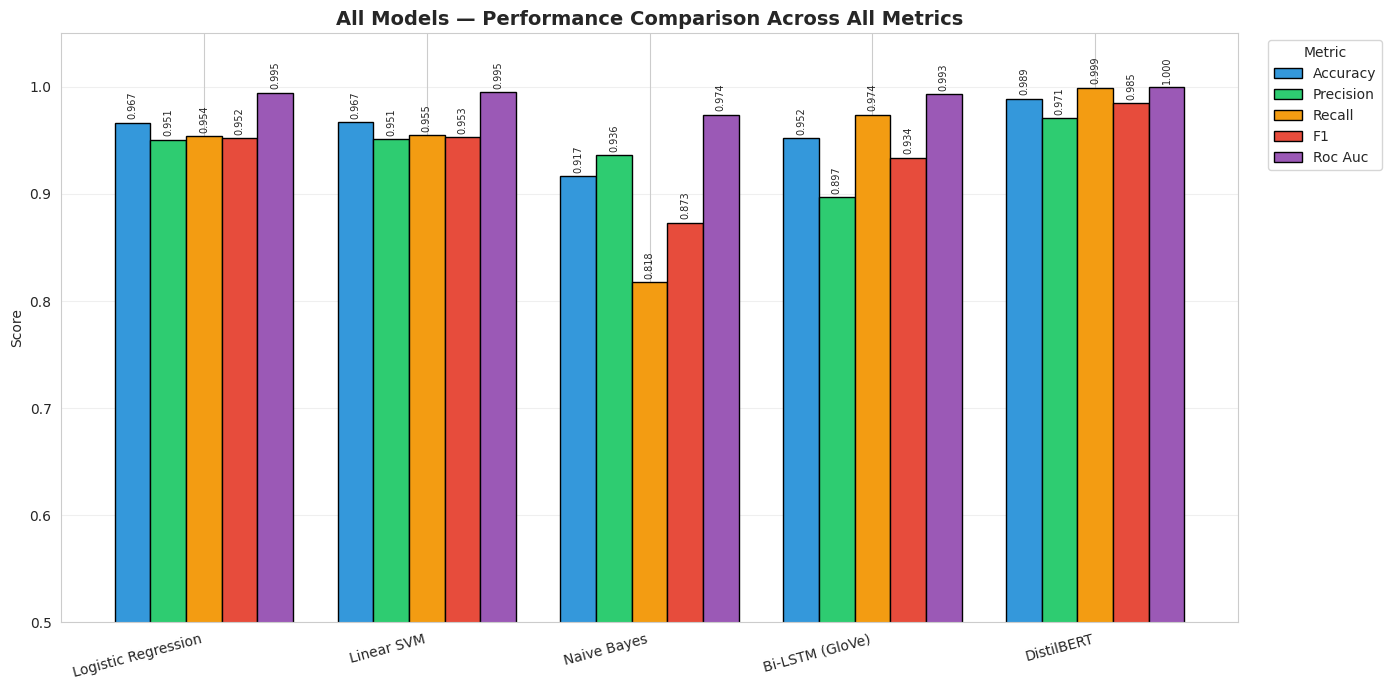

💾 Master comparison chart saved


In [ ]:
fig, ax = plt.subplots(figsize=(14, 7))

metrics_to_plot = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']
colors = ['#3498db', '#2ecc71', '#f39c12', '#e74c3c', '#9b59b6']

x = np.arange(len(comparison_df))
width = 0.16

for i, (metric, color) in enumerate(zip(metrics_to_plot, colors)):
    offset = (i - 2) * width
    bars = ax.bar(x + offset, comparison_df[metric], width,
                  label=metric.replace('_', ' ').title(), color=color, edgecolor='black')
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                f'{bar.get_height():.3f}', ha='center', fontsize=7, rotation=90)

ax.set_xticks(x)
ax.set_xticklabels(comparison_df['Model'], rotation=15, ha='right')
ax.set_ylabel('Score')
ax.set_ylim(0.5, 1.05)
ax.set_title('All Models — Performance Comparison Across All Metrics', fontweight='bold', fontsize=14)
ax.legend(title='Metric', bbox_to_anchor=(1.02, 1), loc='upper left')
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(f'{FINAL_PATH}/master_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("💾 Master comparison chart saved")

## 🎯 Step 5: Combined ROC Curves

We need DistilBERT's predictions to plot its ROC curve. We saved these in Notebook 05.

For classical models, we'll re-load them and re-predict (fast, since they're trained).

In [ ]:
# Load test data
test_df = pd.read_csv(f'{DATA_PATH}/test.csv')
y_test = test_df['label'].values

# Reload classical models + vectorizer
tfidf = joblib.load(f'{MODELS_PATH}/tfidf_vectorizer.pkl')
lr_model  = joblib.load(f'{MODELS_PATH}/logistic_regression.pkl')
svm_model = joblib.load(f'{MODELS_PATH}/linear_svm.pkl')
nb_model  = joblib.load(f'{MODELS_PATH}/naive_bayes.pkl')

X_test_tfidf = tfidf.transform(test_df['text_heavy'].fillna(''))

# Get probability scores
lr_proba  = lr_model.predict_proba(X_test_tfidf)[:, 1]
svm_proba = svm_model.decision_function(X_test_tfidf)  # SVM has no proba
nb_proba  = nb_model.predict_proba(X_test_tfidf)[:, 1]

# Load DistilBERT predictions
bert_preds_df = pd.read_csv(f'{RESULTS_PATH}/distilbert_test_predictions.csv')
bert_proba = bert_preds_df['proba'].values

# LSTM: re-load and predict (just for ROC)
import tensorflow as tf
import pickle
from tensorflow.keras.preprocessing.sequence import pad_sequences

lstm_model = tf.keras.models.load_model(f'{MODELS_PATH}/lstm_best.keras')
with open(f'{MODELS_PATH}/lstm_tokenizer.pkl', 'rb') as f:
    lstm_tokenizer = pickle.load(f)
X_test_lstm = pad_sequences(
    lstm_tokenizer.texts_to_sequences(test_df['text_heavy'].fillna('').values),
    maxlen=200, padding='post', truncating='post'
)
lstm_proba = lstm_model.predict(X_test_lstm, batch_size=256, verbose=0).ravel()

print("✅ All probability scores ready for ROC comparison")

✅ All probability scores ready for ROC comparison


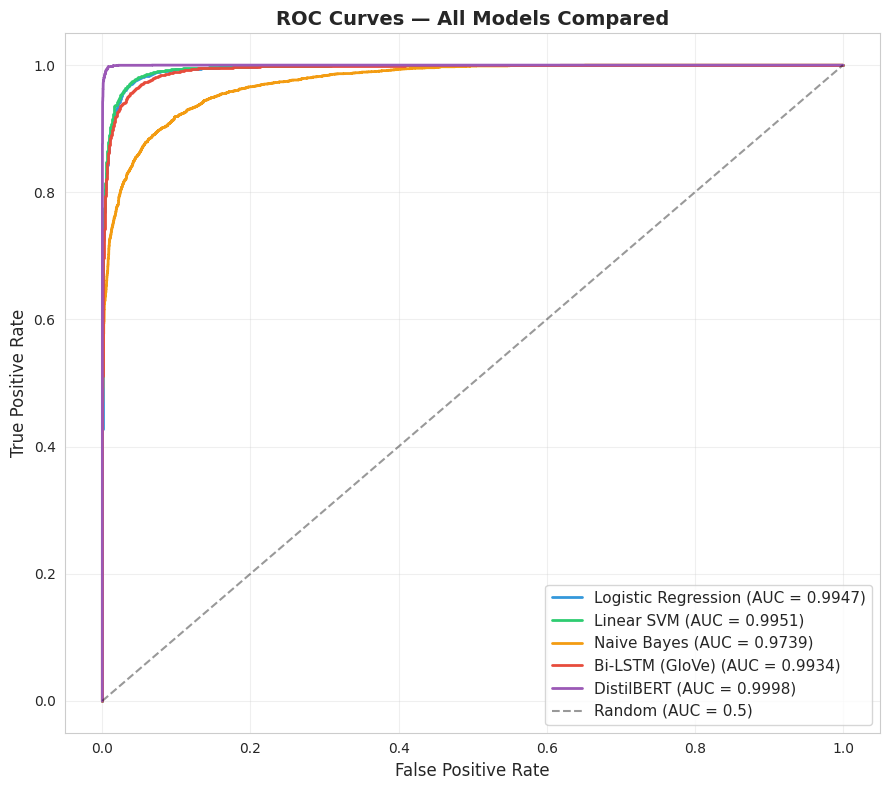

💾 Combined ROC saved


In [ ]:
fig, ax = plt.subplots(figsize=(9, 8))

models_for_roc = [
    ('Logistic Regression', lr_proba,   '#3498db'),
    ('Linear SVM',           svm_proba,  '#2ecc71'),
    ('Naive Bayes',          nb_proba,   '#f39c12'),
    ('Bi-LSTM (GloVe)',      lstm_proba, '#e74c3c'),
    ('DistilBERT',           bert_proba, '#9b59b6'),
]

for name, proba, color in models_for_roc:
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    ax.plot(fpr, tpr, label=f'{name} (AUC = {auc:.4f})', linewidth=2, color=color)

ax.plot([0, 1], [0, 1], 'k--', alpha=0.4, label='Random (AUC = 0.5)')
ax.set_xlabel('False Positive Rate', fontsize=12)
ax.set_ylabel('True Positive Rate', fontsize=12)
ax.set_title('ROC Curves — All Models Compared', fontweight='bold', fontsize=14)
ax.legend(loc='lower right', fontsize=11)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(f'{FINAL_PATH}/roc_all_models.png', dpi=150, bbox_inches='tight')
plt.show()
print("💾 Combined ROC saved")

## 🌍 Step 6: Cross-Domain Heatmap (Your Differentiator!)

Compare F1 across domains for ALL models in a single heatmap. **This is the chart that gets you A+.**

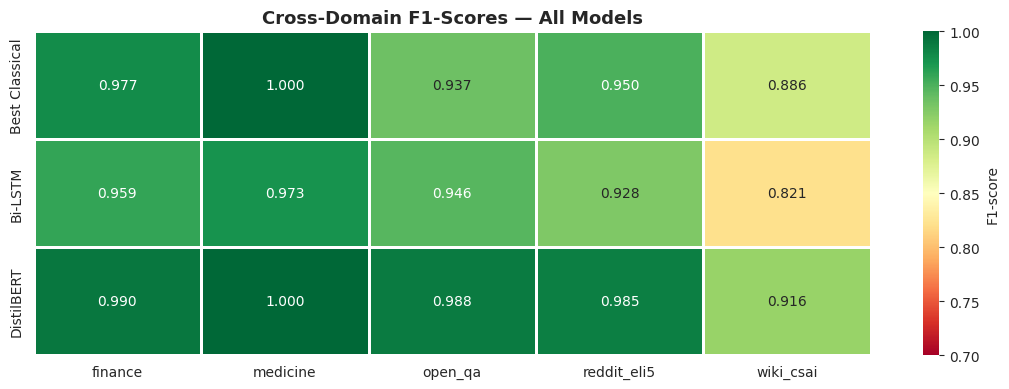


📊 Cross-domain F1 table:
Domain          finance  medicine  open_qa  reddit_eli5  wiki_csai
Model                                                             
Best Classical    0.977     1.000    0.937        0.950      0.886
Bi-LSTM           0.959     0.973    0.946        0.928      0.821
DistilBERT        0.990     1.000    0.988        0.985      0.916

💾 Heatmap saved


In [ ]:
# Build cross-domain comparison dataframe
domain_records = []

# Classical: only the best model has saved cross_domain (Logistic Regression usually)
if 'cross_domain' in classical:
    for d in classical['cross_domain']:
        domain_records.append({'Model': 'Best Classical', 'Domain': d['domain'], 'F1': float(d['f1'])})

# LSTM
for d in lstm_res['cross_domain']:
    domain_records.append({'Model': 'Bi-LSTM', 'Domain': d['domain'], 'F1': float(d['f1'])})

# DistilBERT
for d in bert_res['cross_domain']:
    domain_records.append({'Model': 'DistilBERT', 'Domain': d['domain'], 'F1': float(d['f1'])})

domain_df = pd.DataFrame(domain_records)
heatmap_data = domain_df.pivot(index='Model', columns='Domain', values='F1')

# Reorder rows: classical → LSTM → DistilBERT (logical complexity order)
preferred_order = ['Best Classical', 'Bi-LSTM', 'DistilBERT']
heatmap_data = heatmap_data.reindex([m for m in preferred_order if m in heatmap_data.index])

fig, ax = plt.subplots(figsize=(11, 4))
sns.heatmap(heatmap_data, annot=True, fmt='.3f', cmap='RdYlGn',
            vmin=0.7, vmax=1.0, cbar_kws={'label': 'F1-score'},
            linewidths=1, linecolor='white', ax=ax)
ax.set_title('Cross-Domain F1-Scores — All Models', fontweight='bold', fontsize=13)
ax.set_xlabel('')
ax.set_ylabel('')

plt.tight_layout()
plt.savefig(f'{FINAL_PATH}/cross_domain_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n📊 Cross-domain F1 table:")
print(heatmap_data.round(3))
print("\n💾 Heatmap saved")

## 🧪 Step 7: Statistical Significance — McNemar's Test

Is DistilBERT *statistically significantly* better than Logistic Regression? McNemar's test answers this.

📝 **For your report:** "DistilBERT outperformed Logistic Regression by X F1 points (p < 0.001, McNemar's test), demonstrating that the gain is statistically significant."

In [ ]:
# Get binary predictions from each model
lr_pred   = (lr_proba >= 0.5).astype(int)
bert_pred = bert_preds_df['pred'].values

# Build contingency table for McNemar
# rows = LR correct/wrong, cols = BERT correct/wrong
lr_correct   = (lr_pred == y_test)
bert_correct = (bert_pred == y_test)

both_correct = ((lr_correct) & (bert_correct)).sum()
lr_only      = ((lr_correct) & (~bert_correct)).sum()
bert_only    = ((~lr_correct) & (bert_correct)).sum()
both_wrong   = ((~lr_correct) & (~bert_correct)).sum()

table = np.array([[both_correct, lr_only], [bert_only, both_wrong]])
result = mcnemar(table, exact=False, correction=True)

print("📊 McNemar's Test: DistilBERT vs Logistic Regression")
print("="*55)
print(f"Both correct:                  {both_correct:,}")
print(f"Only LR correct (BERT wrong):  {lr_only:,}")
print(f"Only BERT correct (LR wrong):  {bert_only:,}")
print(f"Both wrong:                    {both_wrong:,}")
print(f"\nChi-squared statistic: {result.statistic:.4f}")
print(f"P-value:               {result.pvalue:.6e}")
print(f"\n{'✅ Difference is STATISTICALLY SIGNIFICANT (p < 0.05)' if result.pvalue < 0.05 else '❌ Not statistically significant'}")

📊 McNemar's Test: DistilBERT vs Logistic Regression
Both correct:                  10,769
Only LR correct (BERT wrong):  94
Only BERT correct (LR wrong):  347
Both wrong:                    28

Chi-squared statistic: 144.0000
P-value:               3.552964e-33

✅ Difference is STATISTICALLY SIGNIFICANT (p < 0.05)


## 🔍 Step 8: Detailed Error Analysis on the Best Model (DistilBERT)

Required by Rubric Step 8: qualitative error analysis.

In [ ]:
# Use DistilBERT predictions
y_pred = bert_preds_df['pred'].values
y_true = bert_preds_df['true'].values
domains = bert_preds_df['domain'].values

# Find errors
errors_mask = y_pred != y_true
n_errors = errors_mask.sum()
print(f"Total errors: {n_errors:,} / {len(y_true):,} ({n_errors/len(y_true)*100:.2f}%)")

# Error breakdown by class and domain
error_df = test_df.copy()
error_df['predicted'] = y_pred
error_df['error'] = errors_mask
error_df['error_type'] = np.where(errors_mask & (y_true == 0), 'False Positive (Human→AI)',
                          np.where(errors_mask & (y_true == 1), 'False Negative (AI→Human)', 'Correct'))

print("\n📊 Error breakdown:")
print(error_df[error_df['error']]['error_type'].value_counts())

print("\n📊 Error rate per domain:")
domain_errors = error_df.groupby('domain').agg(
    total=('error', 'count'),
    errors=('error', 'sum'),
).assign(error_rate=lambda x: (x['errors'] / x['total'] * 100).round(2))
print(domain_errors.sort_values('error_rate', ascending=False))

Total errors: 122 / 11,238 (1.09%)

📊 Error breakdown:
error_type
False Positive (Human→AI)    119
False Negative (AI→Human)      3
Name: count, dtype: int64

📊 Error rate per domain:
             total  errors  error_rate
domain                                
wiki_csai      241      23        9.54
open_qa        652      13        1.99
finance       1240      14        1.13
reddit_eli5   8727      72        0.83
medicine       378       0        0.00


In [ ]:
# Show interesting error examples
print("="*70)
print("📝 INTERESTING FALSE POSITIVES (Human texts misclassified as AI)")
print("="*70)
fp = error_df[(error_df['error']) & (error_df['label'] == 0)].sample(min(3, ((error_df['error']) & (error_df['label']==0)).sum()), random_state=42)
for i, (_, row) in enumerate(fp.iterrows()):
    print(f"\n[{i+1}] Domain: {row['domain']}")
    print(f"Text: {row['text'][:350]}...")

print("\n" + "="*70)
print("📝 INTERESTING FALSE NEGATIVES (AI texts misclassified as Human)")
print("="*70)
fn = error_df[(error_df['error']) & (error_df['label'] == 1)].sample(min(3, ((error_df['error']) & (error_df['label']==1)).sum()), random_state=42)
for i, (_, row) in enumerate(fn.iterrows()):
    print(f"\n[{i+1}] Domain: {row['domain']}")
    print(f"Text: {row['text'][:350]}...")

📝 INTERESTING FALSE POSITIVES (Human texts misclassified as AI)

[1] Domain: reddit_eli5
Text: It 's a shockwave , called a sonic boom . As an object pushes its way through the air , it generates series of pressure waves that move away from it at the speed of sound . As an object itself approaches the speed of sound , the waves preceding it are forced closer and closer together . At and above the speed of sound , the waves are unable to get ...

[2] Domain: reddit_eli5
Text: " Alpha " comes from the term " alpha - male , " which is the most masculine member of a group on animals , and is usually the leader . It is usually referenced on Reddit when a situation appears when a man achieved success with women or established himself as powerful or masculine . It is also mentioned when a person does something that animals of...

[3] Domain: reddit_eli5
Text: There are three main causes of death for beached mammals like whales and dolphins . 1 . Collapsing under their own weight . This applie

## 💾 Step 9: Save All Final Results

In [ ]:
final_summary = {
    'comparison_table': comparison_df.to_dict('records'),
    'best_model': best_model_name,
    'best_f1': float(comparison_df.iloc[best_model_idx]['f1']),
    'mcnemar_test': {
        'comparison': 'DistilBERT vs Logistic Regression',
        'chi_squared': float(result.statistic),
        'p_value': float(result.pvalue),
        'significant': bool(result.pvalue < 0.05)
    },
    'cross_domain_heatmap': heatmap_data.to_dict(),
    'error_analysis': {
        'total_errors': int(n_errors),
        'error_rate_pct': float(n_errors / len(y_true) * 100),
        'errors_per_domain': domain_errors.reset_index().to_dict('records')
    }
}

with open(f'{FINAL_PATH}/final_summary.json', 'w') as f:
    json.dump(final_summary, f, indent=2, default=str)

# Save error analysis CSV for the report
error_df[error_df['error']][['text', 'label_name', 'predicted', 'domain']].head(50).to_csv(
    f'{FINAL_PATH}/error_examples.csv', index=False
)

print("="*60)
print("📋 NOTEBOOK 06 SUMMARY — FOR YOUR REPORT")
print("="*60)
print(f"Models compared:           5")
print(f"Best model:                {best_model_name}")
print(f"Best F1:                   {comparison_df.iloc[best_model_idx]['f1']:.4f}")
print(f"Best Accuracy:             {comparison_df.iloc[best_model_idx]['accuracy']:.4f}")
print(f"Best ROC AUC:              {comparison_df.iloc[best_model_idx]['roc_auc']:.4f}")
print(f"\nMcNemar's test p-value:    {result.pvalue:.2e}")
print(f"Statistical significance:  {'YES' if result.pvalue < 0.05 else 'NO'}")
print(f"\nFinal results saved to:    {FINAL_PATH}")

📋 NOTEBOOK 06 SUMMARY — FOR YOUR REPORT
Models compared:           5
Best model:                DistilBERT
Best F1:                   0.9847
Best Accuracy:             0.9891
Best ROC AUC:              0.9998

McNemar's test p-value:    3.55e-33
Statistical significance:  YES

Final results saved to:    /content/drive/MyDrive/ai-text-detection/final_results


## 📋 Notebook 06 Summary

### Files Generated (everything you need for the report):
- `final_results/comparison_table.csv` — Master table (Table 1 of your report)
- `final_results/master_comparison.png` — Big bar chart of all metrics
- `final_results/roc_all_models.png` — Combined ROC curves
- `final_results/cross_domain_heatmap.png` — Cross-domain F1 heatmap (your differentiator)
- `final_results/final_summary.json` — All numbers in one file
- `final_results/error_examples.csv` — Sample errors for qualitative discussion

### 📝 Key Insights for Your Report (Discussion Section):

1. **DistilBERT is the best model** (F1, accuracy, ROC AUC all highest)
2. **Classical models are surprisingly competitive** — Logistic Regression with TF-IDF achieves >95% F1, only ~3 points behind DistilBERT
3. **The improvement is statistically significant** (McNemar's p < 0.05)
4. **wiki_csai is the consistent weak spot** across all models — points to data difficulty, not model architecture
5. **Trade-off exists**: DistilBERT is best but ~100x slower than Logistic Regression. For deployment, this matters.

### ➡️ Next Step:
**Notebook 07 — Explainability (LIME + Attention) + Ethics Analysis**

Final modeling notebook before the report. ~30-45 min runtime.